In [190]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import missingno as msno

In [191]:
data_titanic = "./data_titanic.csv"
data_energy_nat = "./df_nat.csv"

# Titanic Dataset

## Import data

In [192]:
df_t = pd.read_csv(data_titanic)

In [193]:
df_t

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Visualize Data

### <font color='purple'> Quelle est la répartition des passagers par classe ? </font>
-> Single categorical variable (une seule variable qualitative)

In [194]:
pclass = df_t.groupby('Pclass').size()

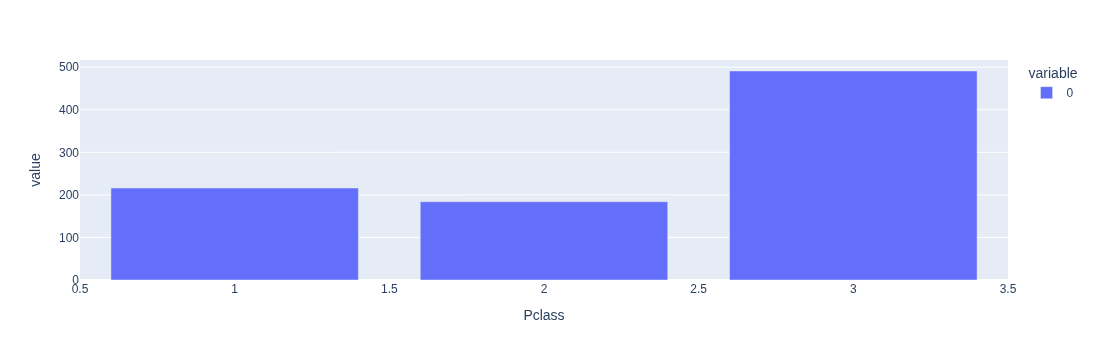

In [195]:
# une seule variable (pclass) = une seule couleur
fig  = px.bar(pclass)
fig.show()

### <font color='purple'> Quelle est la répartition des passagers par sexe ? </font>
-> type of variable(s)?

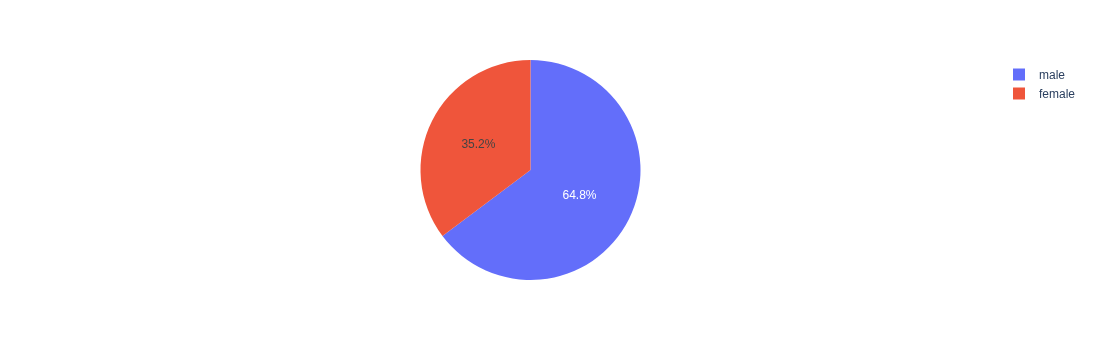

In [196]:
sexe = df_t.groupby('Sex').size().reset_index(name='count')
sexe['pct'] = sexe['count'] * 100 / len(df_t)

fig = px.pie(sexe, names='Sex', values='pct')
fig.show()

### <font color='purple'>Distribution des passagers selon âge et sexe </font>
-> type of variable(s)?

In [197]:
bins = [0, 18, 40, 60, 100]
df_t['AgeGroup'] = pd.cut(df_t['Age'], bins=bins)

distribution = pd.crosstab(df_t['AgeGroup'], df_t['Sex'])
print(distribution)


Sex        female  male
AgeGroup               
(0, 18]        68    71
(18, 40]      145   280
(40, 60]       45    83
(60, 100]       3    19


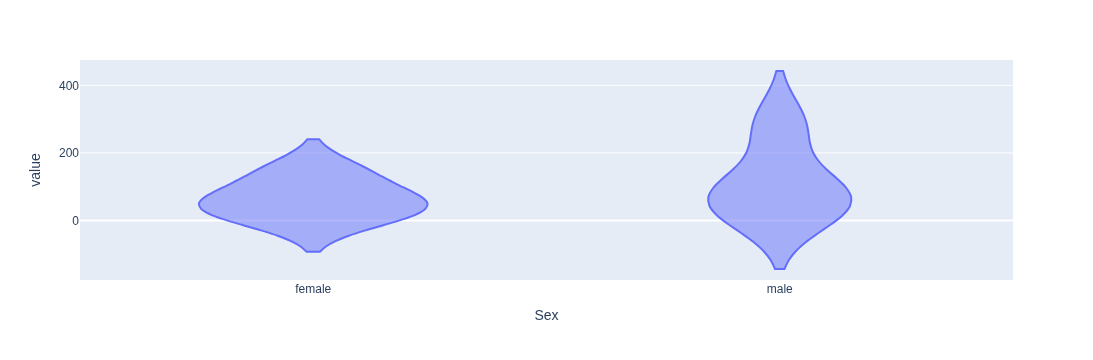

In [198]:
fig = px.violin(distribution)
fig.show()

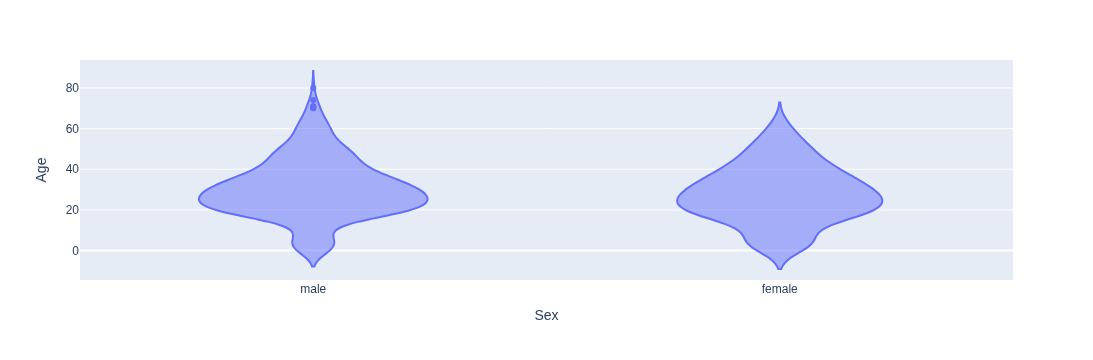

In [199]:
fig = px.violin(df_t, x='Sex', y='Age')
fig.show()

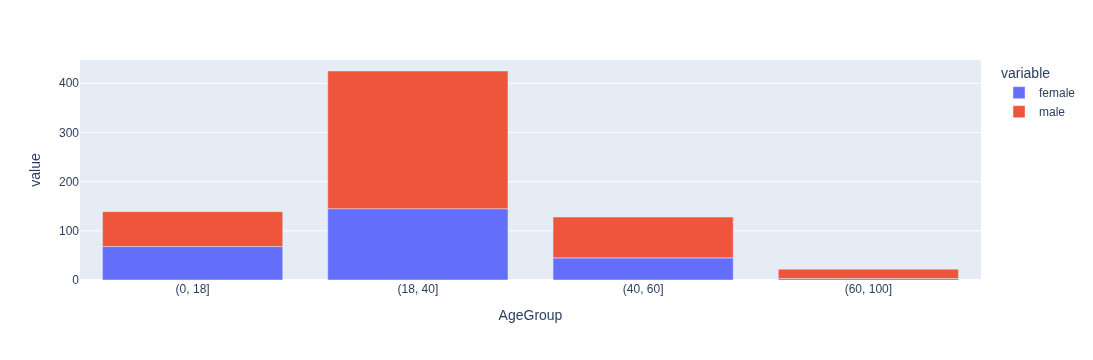

In [200]:
distribution = distribution.reset_index()
distribution['AgeGroup'] = distribution['AgeGroup'].astype(str)

fig = px.bar(distribution, x='AgeGroup', y=['female', 'male'])
fig.show()

In [201]:
distribution

Sex,AgeGroup,female,male
0,"(0, 18]",68,71
1,"(18, 40]",145,280
2,"(40, 60]",45,83
3,"(60, 100]",3,19


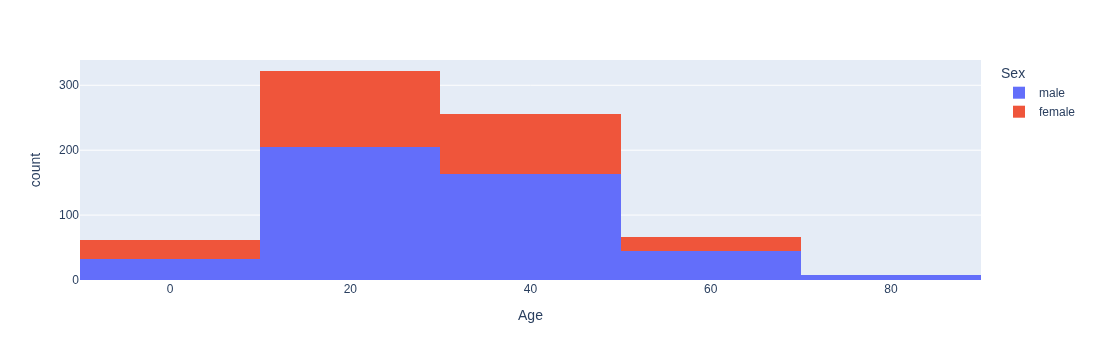

In [202]:
fig = px.histogram(df_t, x='Age', color='Sex', nbins=4, barmode='stack')
fig.show()

### <font color='purple'>Quel est le taux de survie selon le sexe ? l’âge ? la classe ? </font>
-> type of variable(s)?

In [203]:
taux = pd.crosstab(df_t['Sex'], df_t['Survived'], normalize='index') * 100
taux

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


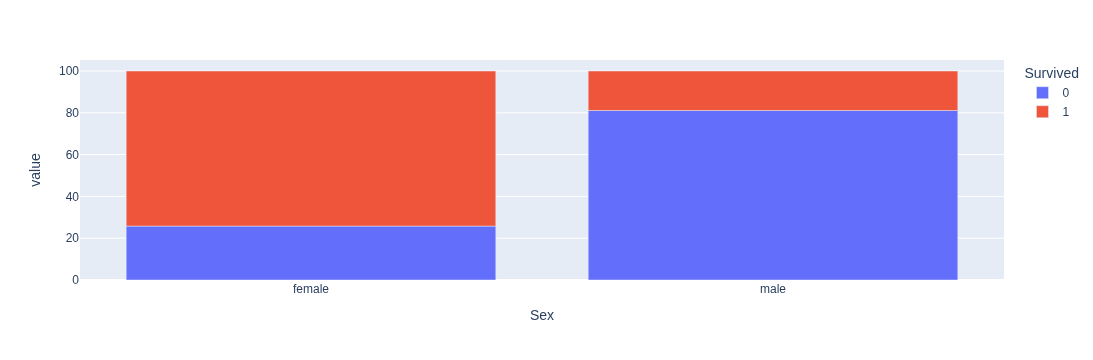

In [204]:
fig = px.bar(taux)
fig.show()

In [205]:
classe = pd.crosstab(df_t['Pclass'], df_t['Survived'], normalize='index') * 100
classe

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


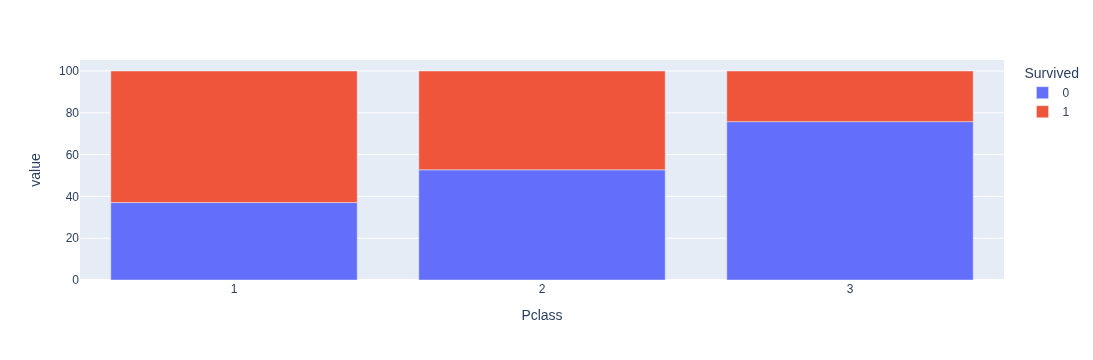

In [206]:
fig = px.bar(classe)
fig.show()

In [207]:

age = pd.crosstab(df_t['AgeGroup'], df_t['Survived'], normalize='index') * 100

age

Survived,0,1
AgeGroup,,
"(0, 18]",49.640288,50.359712
"(18, 40]",61.176471,38.823529
"(40, 60]",60.937500,39.062500
"(60, 100]",77.272727,22.727273


In [208]:
age.index = age.index.astype(str)

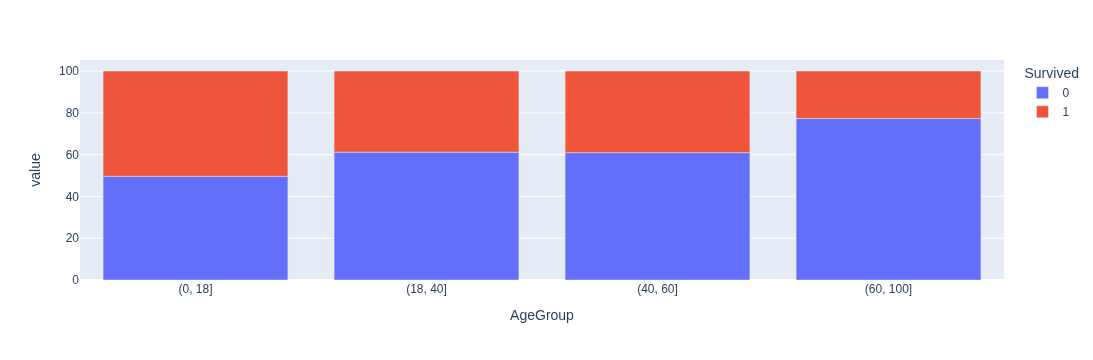

In [209]:
fig = px.bar(age)
fig.show()

### <font color='purple'> Y a-t-il un lien entre prix payé pour le billet et l’âge des passagers ? </font>
-> type of variable(s)?

In [210]:
df_t[['Age', 'Fare']].corr()

,Age,Fare
Age,1.000000,0.096067
Fare,0.096067,1.000000


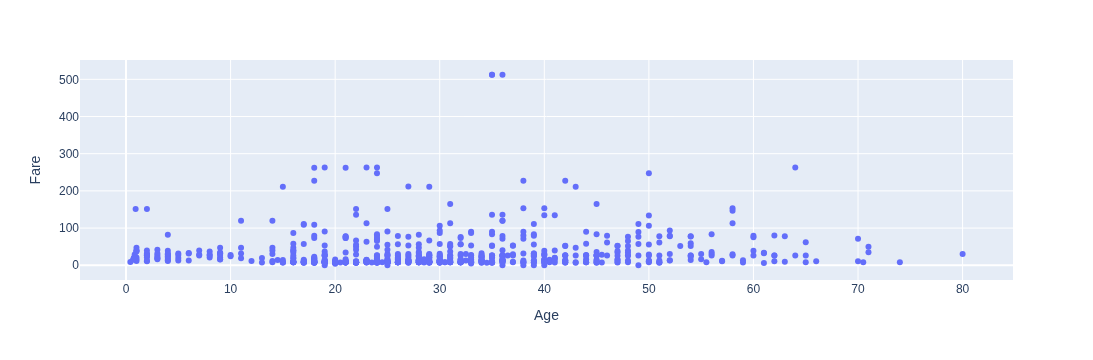

In [211]:
fig = px.scatter(df_t, x='Age', y='Fare')
fig.show()

# Energy Dataset

## Import data

In [212]:
df_e

,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
DateTime,,,,,,,,,,,
2012-01-01 00:00:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
2012-01-01 00:30:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
2012-01-01 01:00:00,56231.0,492.0,25.0,3834.0,51747.0,3536.0,0.0,7598.0,-1730.0,721.0,-9993.0
2012-01-01 01:30:00,56075.0,491.0,25.0,3832.0,51950.0,3526.0,0.0,7299.0,-2134.0,722.0,-9636.0
2012-01-01 02:00:00,55532.0,492.0,25.0,3839.0,51625.0,3535.0,0.0,7159.0,-2449.0,719.0,-9412.0
...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 21:30:00,60580.0,170.0,12.0,3825.0,55679.0,1406.0,-2.0,4648.0,-2572.0,1165.0,-3752.0
2018-12-31 22:00:00,59901.0,146.0,11.0,3568.0,55404.0,1452.0,-2.0,4632.0,-2657.0,1167.0,-3820.0
2018-12-31 22:30:00,60939.0,146.0,11.0,3886.0,55186.0,1569.0,-2.0,4451.0,-2815.0,1165.0,-2660.0


In [213]:
df_e = pd.read_csv(data_energy_nat)

df_e

,DateTime,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
0,2012-01-01 00:00:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
1,2012-01-01 00:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2012-01-01 00:30:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
3,2012-01-01 00:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2012-01-01 01:00:00,56231.0,492.0,25.0,3834.0,51747.0,3536.0,0.0,7598.0,-1730.0,721.0,-9993.0
...,...,...,...,...,...,...,...,...,...,...,...,...
245467,2018-12-31 22:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
245468,2018-12-31 23:00:00,63977.0,146.0,11.0,3910.0,55589.0,1537.0,-2.0,5148.0,-1364.0,1172.0,-2171.0
245469,2018-12-31 23:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
245470,2018-12-31 23:30:00,63803.0,146.0,12.0,3452.0,55404.0,1543.0,-2.0,4688.0,-1474.0,1166.0,-1133.0


In [214]:

df_e.set_index('DateTime', inplace=True)
df_e.dropna(axis=0,how='all',inplace=True)
df_e

,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
DateTime,,,,,,,,,,,
2012-01-01 00:00:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
2012-01-01 00:30:00,58315.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0
2012-01-01 01:00:00,56231.0,492.0,25.0,3834.0,51747.0,3536.0,0.0,7598.0,-1730.0,721.0,-9993.0
2012-01-01 01:30:00,56075.0,491.0,25.0,3832.0,51950.0,3526.0,0.0,7299.0,-2134.0,722.0,-9636.0
2012-01-01 02:00:00,55532.0,492.0,25.0,3839.0,51625.0,3535.0,0.0,7159.0,-2449.0,719.0,-9412.0
...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 21:30:00,60580.0,170.0,12.0,3825.0,55679.0,1406.0,-2.0,4648.0,-2572.0,1165.0,-3752.0
2018-12-31 22:00:00,59901.0,146.0,11.0,3568.0,55404.0,1452.0,-2.0,4632.0,-2657.0,1167.0,-3820.0
2018-12-31 22:30:00,60939.0,146.0,11.0,3886.0,55186.0,1569.0,-2.0,4451.0,-2815.0,1165.0,-2660.0


## Visualize Data

### <font color='purple'> Quels sont les types de variables ? Comment sont distribuées les différentes variables présentées dans ce jeu de données ? </font>

In [215]:
df_e.info()

<class 'pandas.core.frame.DataFrame'>
Index: 122736 entries, 2012-01-01 00:00:00 to 2018-12-31 23:30:00
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Consommation    122736 non-null  float64
 1   Fioul           122736 non-null  float64
 2   Charbon         122736 non-null  float64
 3   Gaz             122736 non-null  float64
 4   Nucléaire       122736 non-null  float64
 5   Eolien          122736 non-null  float64
 6   Solaire         122736 non-null  float64
 7   Hydraulique     122736 non-null  float64
 8   Pompage         122736 non-null  float64
 9   Bioénergies     122736 non-null  float64
 10  Ech. physiques  122736 non-null  float64
dtypes: float64(11)
memory usage: 11.2+ MB


In [216]:
df_e.describe()

,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
count,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000,122736.000000
mean,54575.339884,339.186090,1252.835028,3038.899508,45553.978254,2315.777628,802.891409,7294.958113,-816.434143,898.849702,-6105.612909
std,12184.276144,308.492226,1224.463509,2387.018197,6766.979682,1855.206779,1230.641757,2792.407554,1027.010078,172.446980,3709.975713
min,29477.000000,18.000000,-133.000000,234.000000,26369.000000,21.000000,-2.000000,1387.000000,-3651.000000,441.000000,-17230.000000
25%,45353.000000,160.000000,154.000000,775.000000,40399.000000,993.000000,0.000000,5167.000000,-1631.000000,744.000000,-8686.000000
50%,52868.000000,279.000000,980.000000,2428.000000,44213.000000,1753.000000,11.000000,7136.000000,-168.000000,922.000000,-6335.500000
75%,62987.000000,449.000000,1969.000000,4626.000000,50818.000000,3099.000000,1331.000000,9259.250000,-20.000000,1040.000000,-3940.000000
max,102098.000000,5926.000000,6265.000000,9700.000000,61712.000000,12287.000000,6430.000000,17434.000000,-1.000000,1364.000000,10011.000000


In [217]:
df_e.index = pd.to_datetime(df_e.index)
df = df_e.resample('ME').sum()
df

,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
DateTime,,,,,,,,,,,
2012-01-31,101573076.0,893223.0,1537770.0,8150964.0,85553029.0,3170579.0,233044.0,13372457.0,-1222987.0,1039213.0,-11154331.0
2012-02-29,108364070.0,2070743.0,5111869.0,9966798.0,77305538.0,2242160.0,404651.0,10405047.0,-835944.0,924169.0,768965.0
2012-03-31,85891077.0,875593.0,2921514.0,6575791.0,75117981.0,1950245.0,665576.0,7740614.0,-876794.0,1080601.0,-10160107.0
2012-04-30,79899382.0,705657.0,3298460.0,2813866.0,66152813.0,3137120.0,614459.0,10521234.0,-1027837.0,820778.0,-7137200.0
2012-05-31,70077667.0,526000.0,1706754.0,1234807.0,58064275.0,1944665.0,851728.0,15256472.0,-1293309.0,943855.0,-9157565.0
...,...,...,...,...,...,...,...,...,...,...,...
2018-08-31,64392236.0,157791.0,1001475.0,3639535.0,54566310.0,2810340.0,2655805.0,7753375.0,-1043134.0,1621587.0,-8770809.0
2018-09-30,64955435.0,264782.0,694547.0,3158241.0,60162987.0,3227153.0,2350756.0,6022782.0,-1234225.0,1572207.0,-11263787.0
2018-10-31,73706080.0,536752.0,1578573.0,5162602.0,63112874.0,4982414.0,1619212.0,5792457.0,-1376465.0,1536420.0,-9238739.0


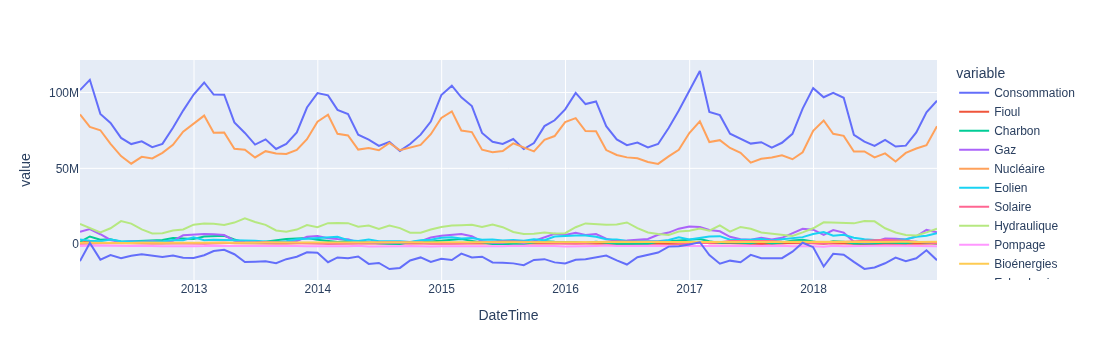

In [218]:
fig = px.line(df)
fig.show()

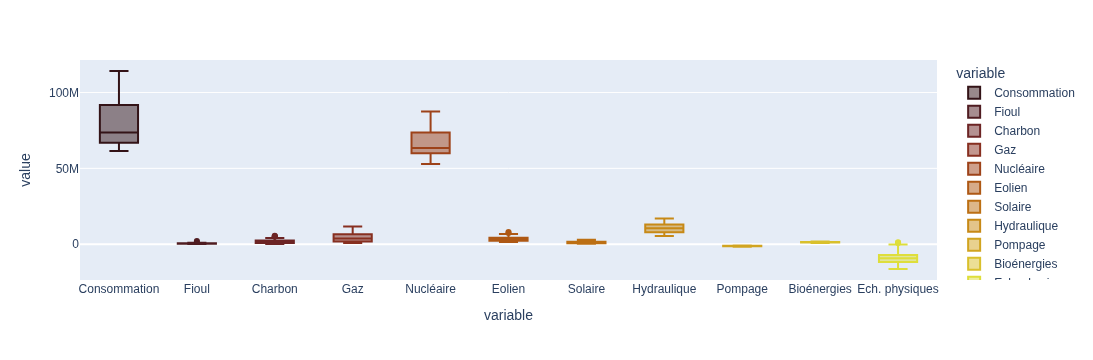

In [220]:
df_long = df.melt(var_name="variable", value_name="value")

fig = px.box(df_long, x="variable", y="value", color="variable",
             color_discrete_sequence=px.colors.sequential.RdBu)
fig.show()

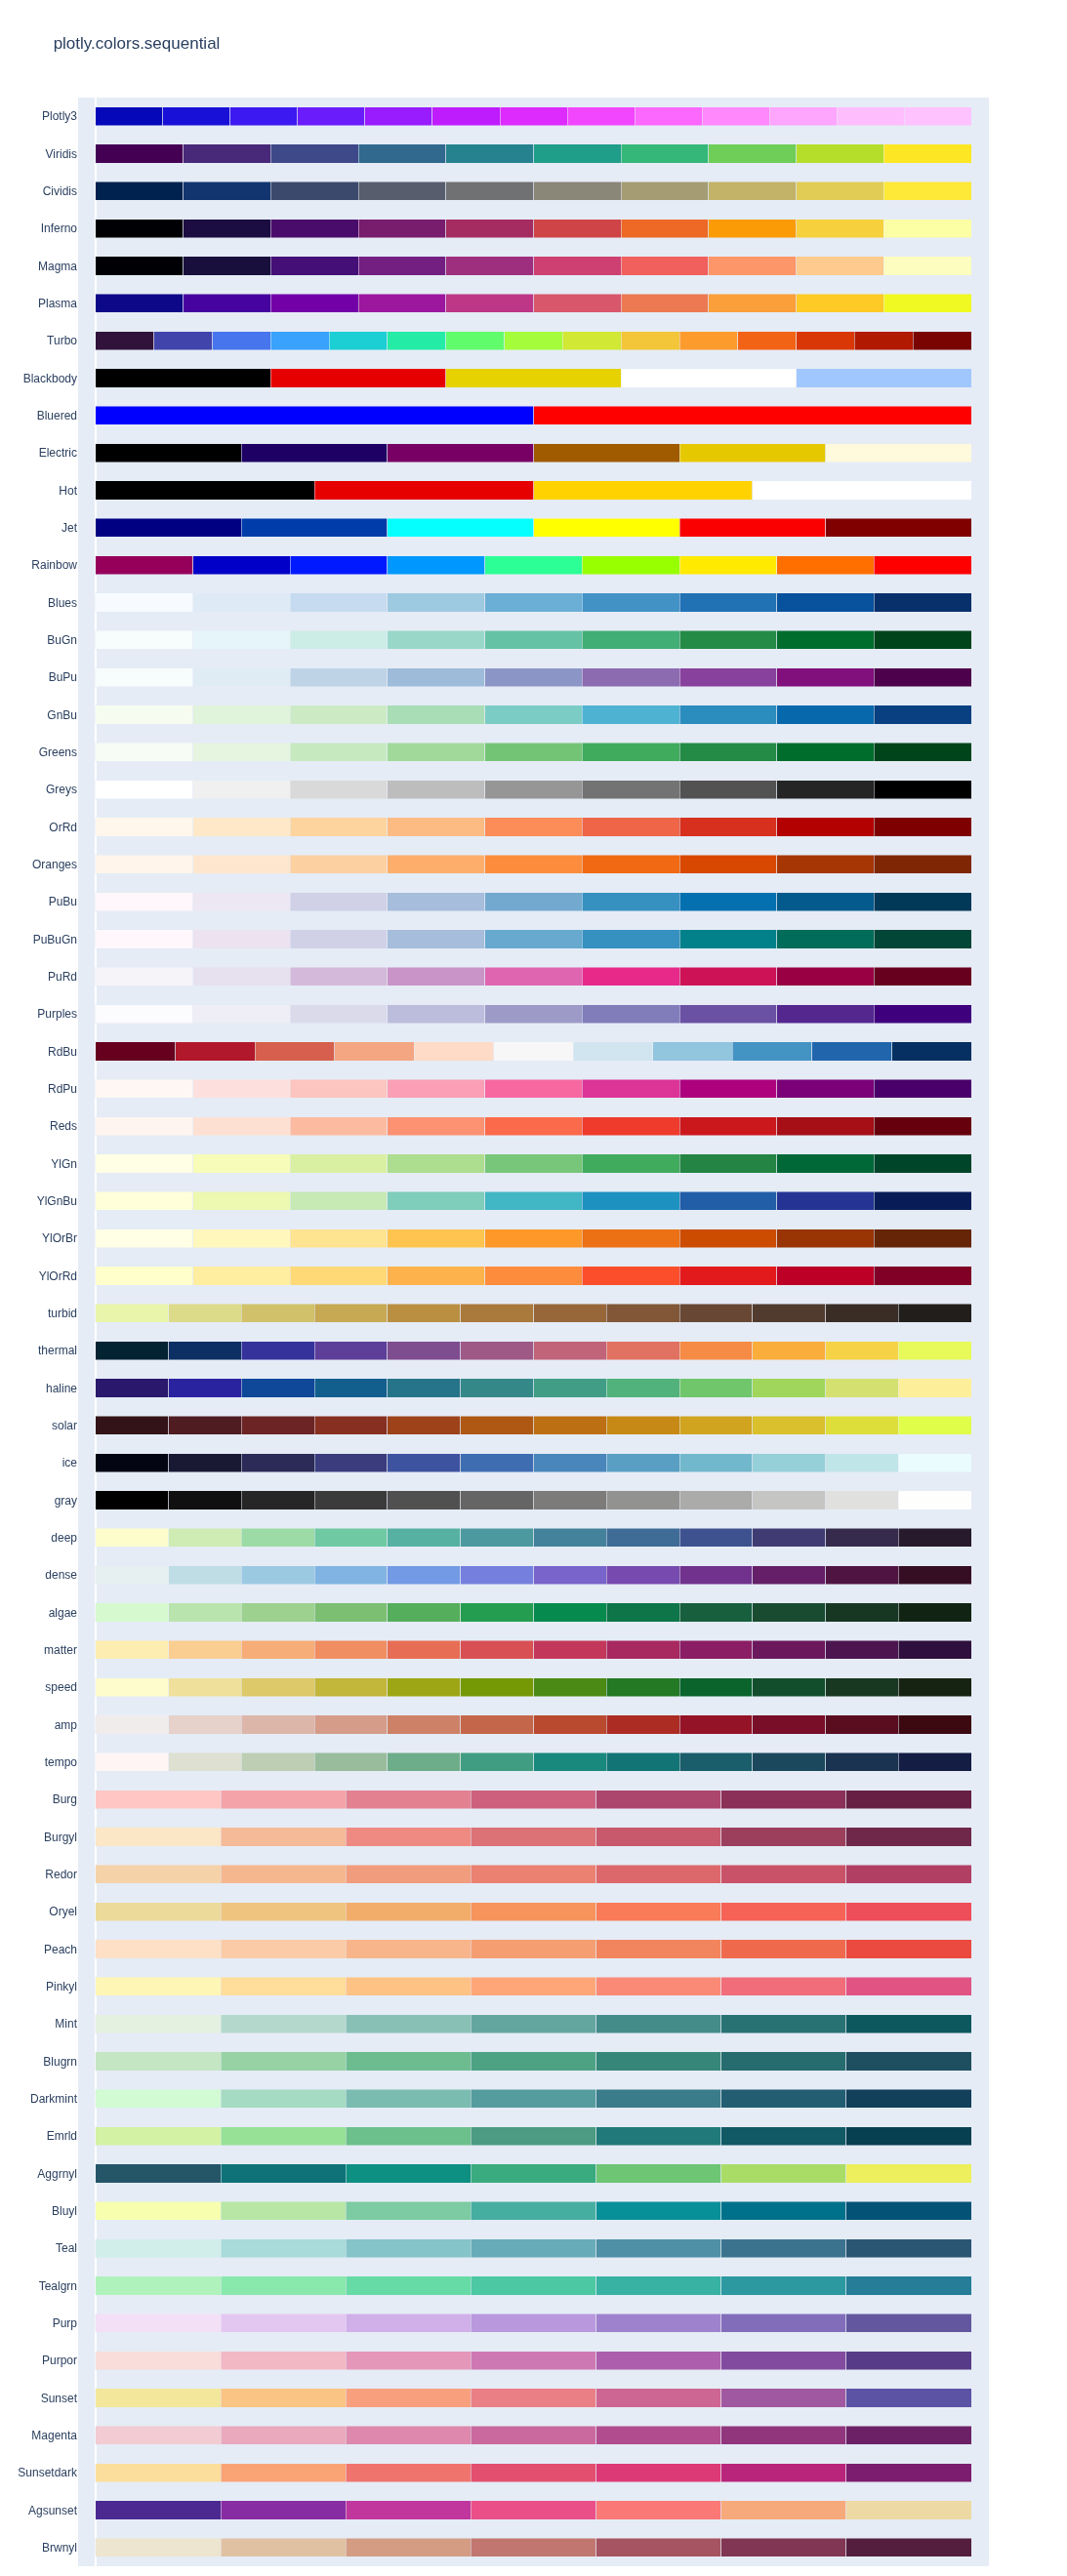

In [221]:
fig = px.colors.sequential.swatches()
fig.show()

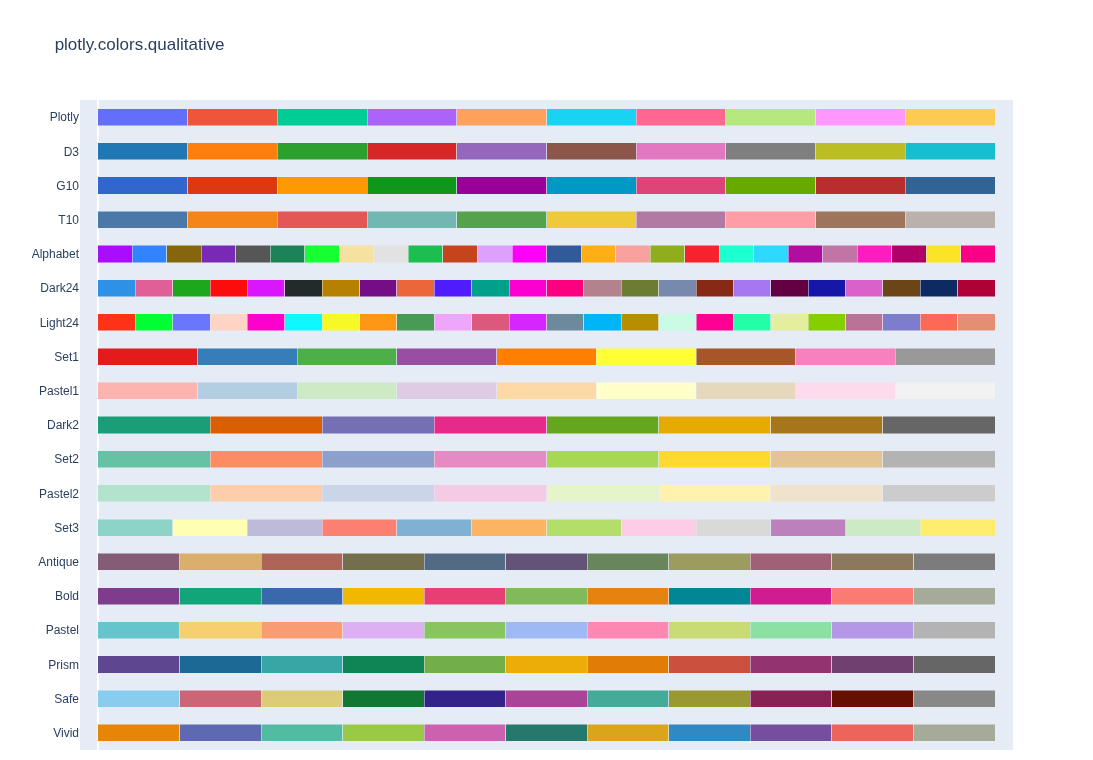

In [222]:
fig = px.colors.qualitative.swatches()
fig.show()

### <font color='purple'> Quelle est l'évolution de la consommation ? </font>

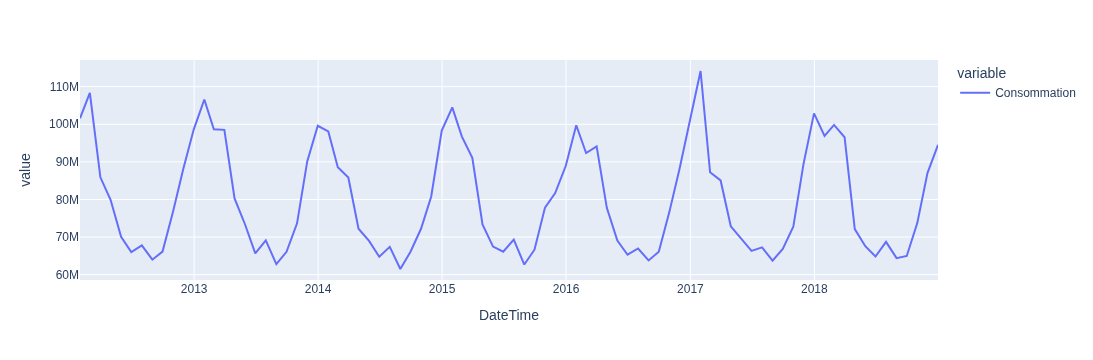

In [223]:
fig = px.line(df['Consommation'])
fig.show()

### <font color='purple'> Quand a-t-on a un excédant / un déficit de production ? </font>

In [224]:
prod = df_e[['Fioul', 'Charbon', 'Gaz', 'Nucléaire', 'Eolien','Solaire', 'Hydraulique', 'Pompage', 'Bioénergies']].sum(axis=1)-df_e['Consommation']
prod

DateTime
2012-01-01 00:00:00    9805.0
2012-01-01 00:30:00    9805.0
2012-01-01 01:00:00    9992.0
2012-01-01 01:30:00    9636.0
2012-01-01 02:00:00    9413.0
                        ...  
2018-12-31 21:30:00    3751.0
2018-12-31 22:00:00    3820.0
2018-12-31 22:30:00    2658.0
2018-12-31 23:00:00    2170.0
2018-12-31 23:30:00    1132.0
Length: 122736, dtype: float64

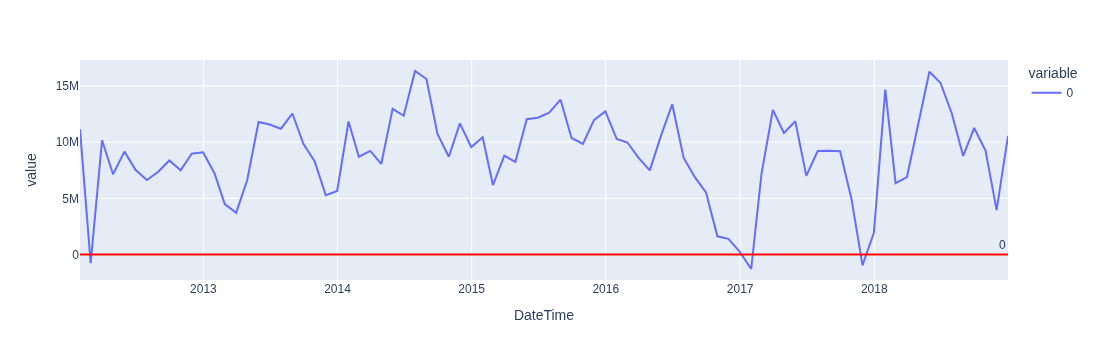

In [225]:

fig = px.line(prod.resample('ME').sum())
fig.add_hline(y=0,  line_color="red", annotation_text="0")

fig.show()

### <font color='purple'> Y a-t-il une corrélation entre les différents types de production ? </font>

In [226]:
df_e.corr()

,Consommation,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
Consommation,1.000000,0.479232,0.581631,0.756740,0.815956,0.229713,-0.022653,0.484211,0.390656,0.091260,0.492990
Fioul,0.479232,1.000000,0.426105,0.414987,0.334240,-0.014267,-0.096906,0.173230,0.135060,-0.200002,0.354179
Charbon,0.581631,0.426105,1.000000,0.432000,0.403444,-0.134766,-0.123320,0.186797,0.252761,-0.321510,0.443492
Gaz,0.756740,0.414987,0.432000,1.000000,0.514744,0.152273,-0.059207,0.119619,0.239341,0.362640,0.496335
Nucléaire,0.815956,0.334240,0.403444,0.514744,1.000000,0.205450,-0.211910,0.305755,0.127496,0.047879,0.063471
Eolien,0.229713,-0.014267,-0.134766,0.152273,0.205450,1.000000,-0.111671,-0.018570,-0.104578,0.310599,-0.107158
Solaire,-0.022653,-0.096906,-0.123320,-0.059207,-0.211910,-0.111671,1.000000,0.026560,0.214649,0.083290,0.039844
Hydraulique,0.484211,0.173230,0.186797,0.119619,0.305755,-0.018570,0.026560,1.000000,0.464810,-0.152645,0.005674
Pompage,0.390656,0.135060,0.252761,0.239341,0.127496,-0.104578,0.214649,0.464810,1.000000,-0.065575,0.159272
Bioénergies,0.091260,-0.200002,-0.321510,0.362640,0.047879,0.310599,0.083290,-0.152645,-0.065575,1.000000,0.005496


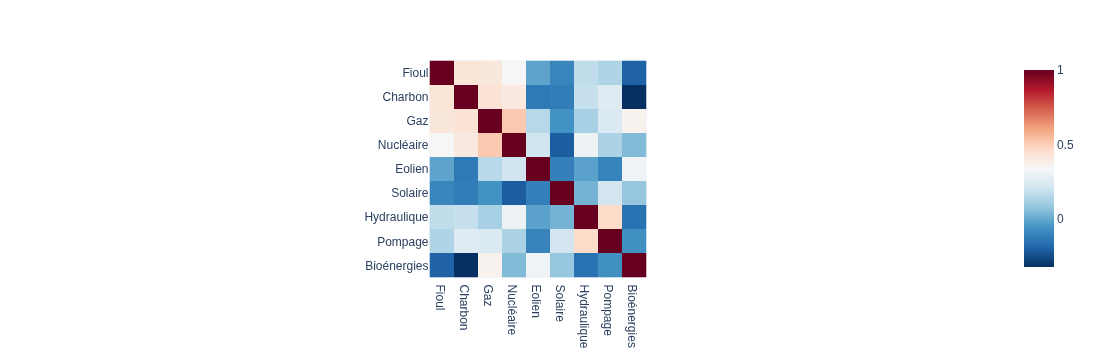

In [227]:
#fig = px.imshow(df_e.corr(), color_continuous_scale=px.colors.sequential.RdBu)
temp = df_e.drop(columns=['Consommation','Ech. physiques'])
fig = px.imshow(temp.corr(), color_continuous_scale='RdBu_r')
fig.show()